# 02 — Structural sparsity and visualization

**Objectives.** Distinguish structural and numerical zeros, inspect CCS metadata, and visualize Jacobian patterns.

CasADi stores sparse matrices in compressed-column storage (CCS). A *structural nonzero* reserves a graph entry even if its current numerical value is zero. `nnz()` counts structural entries; `numel()` counts every matrix location.


### Editable lesson setup

This cell makes the checked-out repository available to the notebook without
installing it as a Python package. It searches the current directory and its
parents for `casadi_tutorial/`, adds that repository root to `sys.path`, and
enables IPython's `autoreload` extension. With autoreload enabled, changes to the
editable CSTR, UR5e, integration, plotting, and diagnostic modules are picked up
before later cells execute.

There is no mathematical transformation in this setup cell. Its role is to make
the relationship between notebook code and local source code explicit:

$$
\text{notebook import} \longrightarrow
\text{current repository source},
$$

rather than resolving an older installed wheel or editable package.


In [4]:
# Make repository-local helpers importable without installing a package.
import sys
from pathlib import Path

repository_root = next(
    candidate
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "casadi_tutorial").is_dir()
)
if str(repository_root) not in sys.path:
    sys.path.insert(0, str(repository_root))

# Autoreload picks up edits to tutorial models before each notebook cell runs.
ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic("load_ext", "autoreload")
    ipython.run_line_magic("autoreload", "2")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Construct and inspect a structural sparsity pattern

`Sparsity.triplet` constructs a matrix pattern from zero-based row and
column coordinates. `DM(sparsity, values)` then assigns one stored value
to each structural entry. Structural sparsity is intentionally different
from numerical nonzero detection: an entry can be stored in the graph
even when its current numerical value is zero.

If $\mathcal{S}$ denotes the set of stored coordinates, this example uses

$$
\mathcal{S}=\{(0,0),(1,1),(2,2),(3,3),(4,4),(0,4)\}.
$$

Therefore `nnz()` reports $|\mathcal{S}|=6$, whereas `numel()` reports
the dense size $5\cdot5=25$. `colind()` and `row()` expose CasADi's
compressed-column storage, and `plot_sparsity` visualizes the structure
without discarding the explicitly stored zero.


shape: (5, 5) structural nonzeros: 6 dense elements: 25
CCS column offsets: [0, 1, 2, 3, 4, 6]
stored row indices: [0, 1, 2, 3, 0, 4]


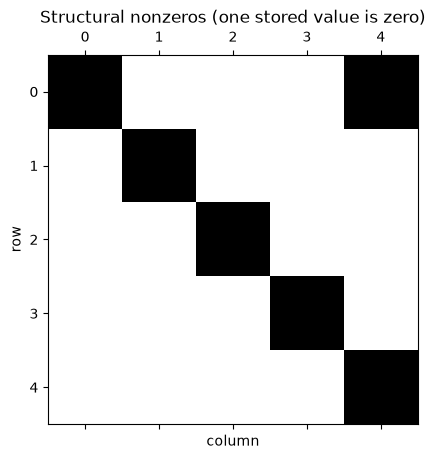

In [5]:
import casadi as ca
import matplotlib.pyplot as plt

from casadi_tutorial.plotting import plot_sparsity

# Sparsity.triplet declares structural entries with zero-based row/column lists.
sparsity = ca.Sparsity.triplet(
    5,
    5,
    [0, 1, 2, 3, 4, 0],
    [0, 1, 2, 3, 4, 4],
)

# DM(sparsity, values) stores one value at every declared structural entry.
# A stored numerical zero remains part of the structural sparsity pattern.
sparse_matrix = ca.DM(sparsity, [1, 0, 3, 4, 5, 6])
print(
    "shape:",
    sparse_matrix.shape,
    "structural nonzeros:",
    sparse_matrix.nnz(),
    "dense elements:",
    sparse_matrix.numel(),
)
print("CCS column offsets:", sparse_matrix.sparsity().colind())
print("stored row indices:", sparse_matrix.sparsity().row())

plot_sparsity(
    sparse_matrix,
    title="Structural nonzeros (one stored value is zero)",
)
plt.show()

### Differentiate a sparse vector expression

The cell creates a three-output SX expression and asks `ca.jacobian` for
all output derivatives with respect to six inputs. CasADi propagates
structural dependencies while constructing the derivative, so the
resulting Jacobian records only entries that can be nonzero.

The expression and its Jacobian are

$$
f(x)=\begin{bmatrix}
x_0^2+x_2\\
\sin(x_1)+x_4x_5\\
x_3
\end{bmatrix},\qquad
J(x)=\frac{\partial f}{\partial x}=
\begin{bmatrix}
2x_0&0&1&0&0&0\\
0&\cos(x_1)&0&0&x_5&x_4\\
0&0&0&1&0&0
\end{bmatrix}.
$$

The six structurally nonzero entries explain the `nnz()` assertion and
the pattern displayed by the plot.


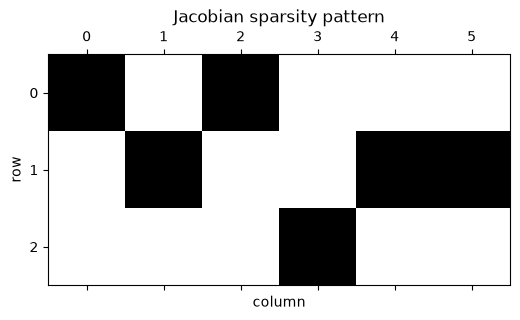

@1=1, 
[[(symbolic_vector_0+symbolic_vector_0), 00, @1, 00, 00, 00], 
 [00, cos(symbolic_vector_1), 00, 00, symbolic_vector_5, symbolic_vector_4], 
 [00, 00, 00, @1, 00, 00]]


In [6]:
symbolic_vector = ca.SX.sym("symbolic_vector", 6)
expression = ca.vertcat(
    symbolic_vector[0] ** 2 + symbolic_vector[2],
    ca.sin(symbolic_vector[1]) + symbolic_vector[4] * symbolic_vector[5],
    symbolic_vector[3],
)

# jacobian differentiates every output with respect to every input and
# preserves the exact structural zero pattern of the derivative matrix.
jacobian = ca.jacobian(expression, symbolic_vector)
figure, axes = plt.subplots(figsize=(6, 3))
plot_sparsity(jacobian, ax=axes, title="Jacobian sparsity pattern")
plt.show()

assert jacobian.nnz() == 6
print(jacobian)

## Why sparsity matters

A multiple-shooting Jacobian is block-banded: each continuity equation touches only neighboring states and one control. Sparse factorization exploits this locality. Accidentally densifying a graph increases derivative storage and KKT factorization cost.

**Common mistake:** `ca.DM.zeros(n,n)` is structurally dense; construct a `Sparsity` pattern when the structure matters. **Recap:** plot the Jacobian and Hessian structure before tuning a large solver.
